# DiT 与生成数据流

这里默认使用 Flow Matching：在噪声 t=0 与图像 t=1 之间作直线插值，网络预测速度。也可以将生成方法改为 Diffusion，训练目标会改为噪声，采样使用逐步去噪。

两种方法都通过 Stream 准备数据，无需另外调用批次准备函数。默认只训练两步，再采样八步，用于理解流程；结果通常仍是噪声。请在 `examples` 目录运行。

In [1]:
from qutai import Stream, generation, nn, visualization
from datasets import load_mnist

## 1. 准备真实图像

与 LeNet、ViT 一样，使用 `load_mnist` 读取数据，再交给 `Stream` 分批。读取器按需将像素转成 0–1，下方先预览两张图。生成训练所需的 −1–1 转换会由 Stream 自动完成。


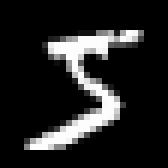
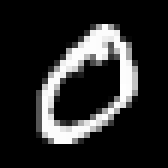

In [2]:
pixels, labels = load_mnist("train")
images, _ = next(iter(Stream(pixels, labels, batch_size=2, shuffle=False, progress=False)))
visualization.ImageCombine([visualization.Image.from_tensor(image, value_range=(0, 1)) for image in images], columns=2, title="真实 MNIST")

## 2. 组合网络与生成方法

DiT 接收图片与时间，返回同形状的预测。生成方法决定时间、噪声、训练目标和采样步骤。
将下面的 `generation.FlowMatching(steps=8)` 换成 `generation.Diffusion(steps=8)`，其余数据流和训练代码保持相同。

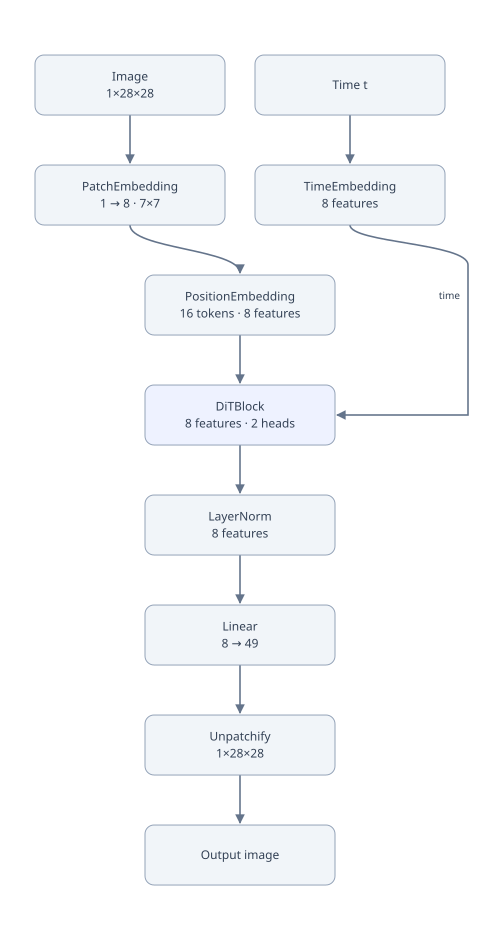

In [3]:
method = generation.FlowMatching(steps=8)
network = nn.DiT(1, 28, patch_size=7, features=8, heads=2, hidden_features=16)
model = generation.Model(network, method=method)
optimizer = nn.SGD(model, learning_rate=0.001)
loss_function = nn.MSE()
visualization.Network(model)

## 3. 用 Stream 准备训练数据

直接将生成方法传给 Stream。它会在分批后完成图片范围转换，并自动准备 `(inputs, times, targets)`。

只取四张图片，每批两张，因此训练循环一共更新两次。下图展示一张训练输入及其训练目标：Flow Matching 的目标是速度，Diffusion 的目标是噪声。

每张图对应的时间： [0.1296706935294618, 0.7047992142984214]



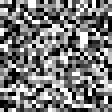
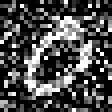

In [4]:
data = Stream(pixels, method=method, batch_size=2, limit=4, progress=False)
inputs, times, targets = next(iter(data))
print("每张图对应的时间：", times)
visualization.ImageCombine([visualization.Image.from_tensor(batch[0], scale=4) for batch in (inputs, targets)], columns=2, labels=["训练输入", "训练目标"])

## 4. 按轮次和批次训练

与 LeNet 一样，外层控制训练轮次，内层遍历数据流；每轮结束打印最后一批的损失。
默认训练 1 轮，每轮 2 批，共更新两次。每轮重新打乱图片，每批重新生成时间和噪声。
DiT 的零初始化可能使部分参数最初几步的梯度为零。

In [8]:
for epoch in range(2):
    for inputs, times, targets in data:
        optimizer.zero_grad()
        loss = loss_function(model(inputs, times), targets)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch}/{2}  最后一批 MSE {loss.item():.6f}")

epoch 0/2  最后一批 MSE 1.973845
epoch 1/2  最后一批 MSE 1.910545


## 5. 从噪声采样

轨迹包含初始噪声与八次更新。每隔两步展示一张图，最后一张是最终结果。
原始状态可以超出 −1–1；只有显示图片时才裁剪像素，模型状态保持原值。

最终数值范围： -3.0937280536432223 3.8058540589991035



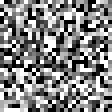
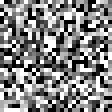
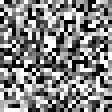
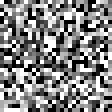
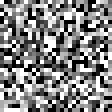

In [9]:
frames = model.trajectory()
samples = frames[-1]
print("最终数值范围：", min(samples.values), max(samples.values))
visualization.ImageCombine([visualization.Image.from_tensor(frame[0], scale=4) for frame in frames[::2]], columns=5, labels=["噪声", "第 2 步", "第 4 步", "第 6 步", "第 8 步"])